In [1]:

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

print("Python is ready!")
print("Python version:", sys.version.split()[0])
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("SciPy version:", scipy.__version__)


Python is ready!
Python version: 3.14.6
NumPy version: 2.5.4
Pandas version: 3.0.6
SciPy version: 1.18.1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

print("Python is ready!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)

Python is ready!
NumPy: 2.5.4
Pandas: 3.0.6
SciPy: 1.18.1


Total samples: 2000
Sampling rate: 1000 Hz
Duration: 2 seconds


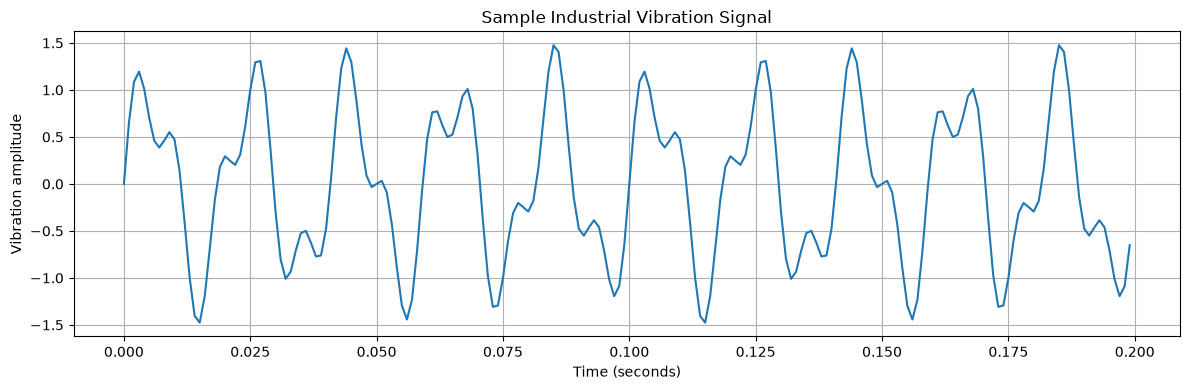

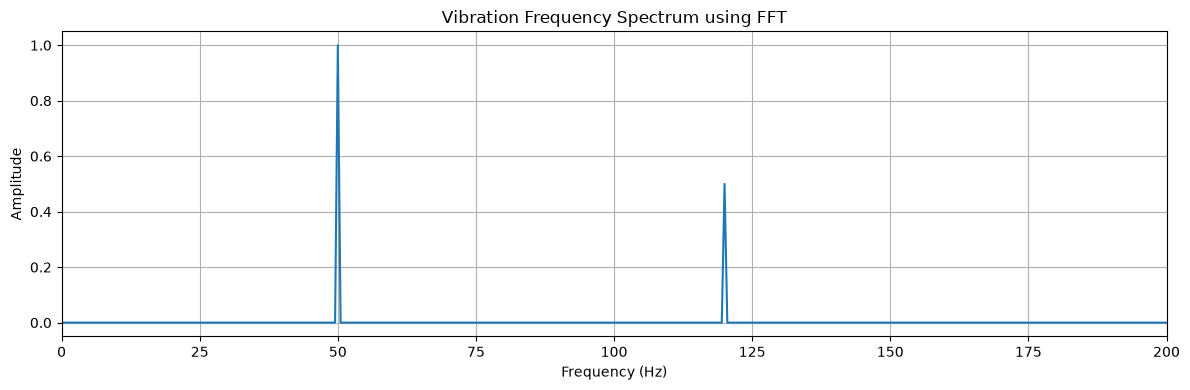


Strongest frequency peaks:
50.0 Hz : 1.000
120.0 Hz : 0.500
120.5 Hz : 0.000
119.5 Hz : 0.000
384.0 Hz : 0.000


In [3]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import rfft, rfftfreq

# 1. Generate sample sensor data
sampling_rate = 1000  # Samples per second (Hz)
duration = 2           # Duration in seconds

time = np.arange(0, duration, 1 / sampling_rate)

# Sample vibration signal with two frequencies
signal = (
    1.0 * np.sin(2 * np.pi * 50 * time)
    + 0.5 * np.sin(2 * np.pi * 120 * time)
)

print("Total samples:", len(signal))
print("Sampling rate:", sampling_rate, "Hz")
print("Duration:", duration, "seconds")

# 2. Plot vibration signal in the time domain
plt.figure(figsize=(12, 4))
plt.plot(time[:200], signal[:200])
plt.xlabel("Time (seconds)")
plt.ylabel("Vibration amplitude")
plt.title("Sample Industrial Vibration Signal")
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. Apply Fast Fourier Transform (FFT)
fft_values = rfft(signal)
frequencies = rfftfreq(len(signal), d=1 / sampling_rate)

# Calculate the amplitude spectrum
amplitudes = (2 / len(signal)) * np.abs(fft_values)
amplitudes[0] /= 2

# 4. Plot frequency spectrum
plt.figure(figsize=(12, 4))
plt.plot(frequencies, amplitudes)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Vibration Frequency Spectrum using FFT")
plt.xlim(0, 200)
plt.grid(True)
plt.tight_layout()
plt.show()

# 5. Display strongest frequency peaks
peak_indices = np.argsort(amplitudes[1:])[-5:] + 1
peak_indices = peak_indices[np.argsort(amplitudes[peak_indices])[::-1]]

print("\nStrongest frequency peaks:")
for index in peak_indices:
    print(f"{frequencies[index]:.1f} Hz : {amplitudes[index]:.3f}")
